# 05 — Leave-One-Condition-Out Validation & Counterfactual Prediction of NASA's Exploration Atmosphere ($56.54\text{ kPa} / 34\%\ \text{O}_2$) (WP5)

**Objective:** Validate out-of-condition generalization across unseen $(P_{\text{total}}, p\text{O}_2)$ regimes using Leave-One-Condition-Out (LOCO) cross-validation, and generate quantitative counterfactual predictions of *Arabidopsis* shoot and root pathway and hub-gene responses at NASA's exact Exploration Atmosphere setpoints:
1. **Exploration Habitat Setpoint:** $56.54\text{ kPa}$ ($8.2\text{ psia}$), $34\%\ \text{O}_2$ ($p\text{O}_2 = 19.22\text{ kPa}$, gas diffusivity factor $D/D_0 = 1.72\times$).
2. **Pre-EVA Staged Decompression Setpoint:** $70.33\text{ kPa}$ ($10.2\text{ psia}$), $26.5\%\ \text{O}_2$ ($p\text{O}_2 = 18.64\text{ kPa}$, $D/D_0 = 1.38\times$).
3. **Uncompensated $56.54\text{ kPa}$ Air Counterfactual:** $56.54\text{ kPa}$, $21\%\ \text{O}_2$ ($p\text{O}_2 = 11.87\text{ kPa}$, $D/D_0 = 1.72\times$).

## 1. Leave-One-Condition-Out (LOCO) Generalization Across Unseen $(P_{\text{total}}, p\text{O}_2)$ Regimes

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import Image, display

PROJECT_DIR = Path("/Users/drb_laptop/Documents/Exploration_atmosphere_Biomni_lab_downloads_20261016_234156/arabidopsis_exploration_atmosphere")
s6b = pd.read_csv(PROJECT_DIR / "manuscript/tables/Table_S6B_Leave_One_Condition_Out_Validation.csv")
print("=== Mean LOCO Performance Across Held-Out Atmospheric Regimes ===")
print(s6b.groupby("Model")[["Pearson_r_12Pathways", "Spearman_rho_12Pathways", "RMSE_dlog2", "MAE_dlog2"]].mean().round(4).to_string())
print("\n=== Per-Condition LOCO Performance (TabPFN v2 vs Baselines) ===")
print(s6b[s6b["Model"].isin(["TabPFN v2", "TabPFN v2 (PHE)", "Ridge", "RandomForest"])].to_string(index=False))

=== Mean LOCO Performance Across Held-Out Atmospheric Regimes ===
                 Pearson_r_12Pathways  Spearman_rho_12Pathways  RMSE_dlog2  MAE_dlog2
Model                                                                                
RandomForest                   0.6571                   0.5993      0.1918     0.1325
Ridge                          0.6579                   0.6329      0.1881     0.1334
TabPFN v2                      0.7387                   0.6650      0.1502     0.1125
TabPFN v2 (PHE)                0.6310                   0.5559      0.1800     0.1345

=== Per-Condition LOCO Performance (TabPFN v2 vs Baselines) ===
           Held_Out_Regime Organ           Model  Pearson_r_12Pathways  Spearman_rho_12Pathways  RMSE_dlog2  MAE_dlog2
Hypobaria_50kPa_NormoxicO2 Shoot TabPFN v2 (PHE)                0.6634                   0.6224      0.1160     0.0874
Hypobaria_50kPa_NormoxicO2 Shoot       TabPFN v2                0.8316                   0.8392      0.0889     0.0

## 2. Counterfactual Pathway & Molecular Hub Predictions at NASA's Exploration Atmosphere Setpoints (`Table_S6A`)

In [2]:
s6a = pd.read_csv(PROJECT_DIR / "manuscript/tables/Table_S6A_NASA_Exploration_Atmosphere_Counterfactual_Predictions.csv", index_col=0)
pws = [
    "ERF_VII_Core_Hypoxia_Anaerobic",
    "Oxylipin_JA_Chloroplast_Galactolipid",
    "ROS_Redox_Calcium_HeatShock",
    "Phenylpropanoid_Sinapate_Flavonol",
    "Photosynthesis_Carbon_Fixation_LHC",
    "AtPDC1 (253416_at)" if "AtPDC1 (253416_at)" in s6a.columns else "PDC1 (253416_at)",
    "TCH4 (247925_at)",
    "LOX2 (252618_at)",
]
sub = s6a[s6a["Organ_Stage"].isin(["Shoot_10d", "Root_10d"])][["Setpoint_Name", "Organ_Stage", "P_total_kPa", "pO2_kPa"] + pws]
print(sub.round(3).to_string(index=False))

Setpoint_Name Organ_Stage  P_total_kPa  pO2_kPa  ERF_VII_Core_Hypoxia_Anaerobic  Oxylipin_JA_Chloroplast_Galactolipid  ROS_Redox_Calcium_HeatShock  Phenylpropanoid_Sinapate_Flavonol  Photosynthesis_Carbon_Fixation_LHC  PDC1 (253416_at)  TCH4 (247925_at)  LOX2 (252618_at)
                      Control_ISS_97kPa_21pctO2   Shoot_10d        97.00    20.37                          -0.061                                 0.071                        0.074                              0.008                               0.028             0.005            -0.101             0.263
                      Control_ISS_97kPa_21pctO2    Root_10d        97.00    20.37                           0.029                                -0.024                        0.025                              0.044                              -0.080             0.181             0.137             0.046
           NASA_Staged_PreEVA_70.3kPa_26.5pctO2   Shoot_10d        70.33    18.64                          -0.070   

## 3. Visualization: NASA Exploration Atmosphere ($56.54\text{ kPa} / 34\%\ \text{O}_2$) Counterfactual Synthesis (Figure 6)

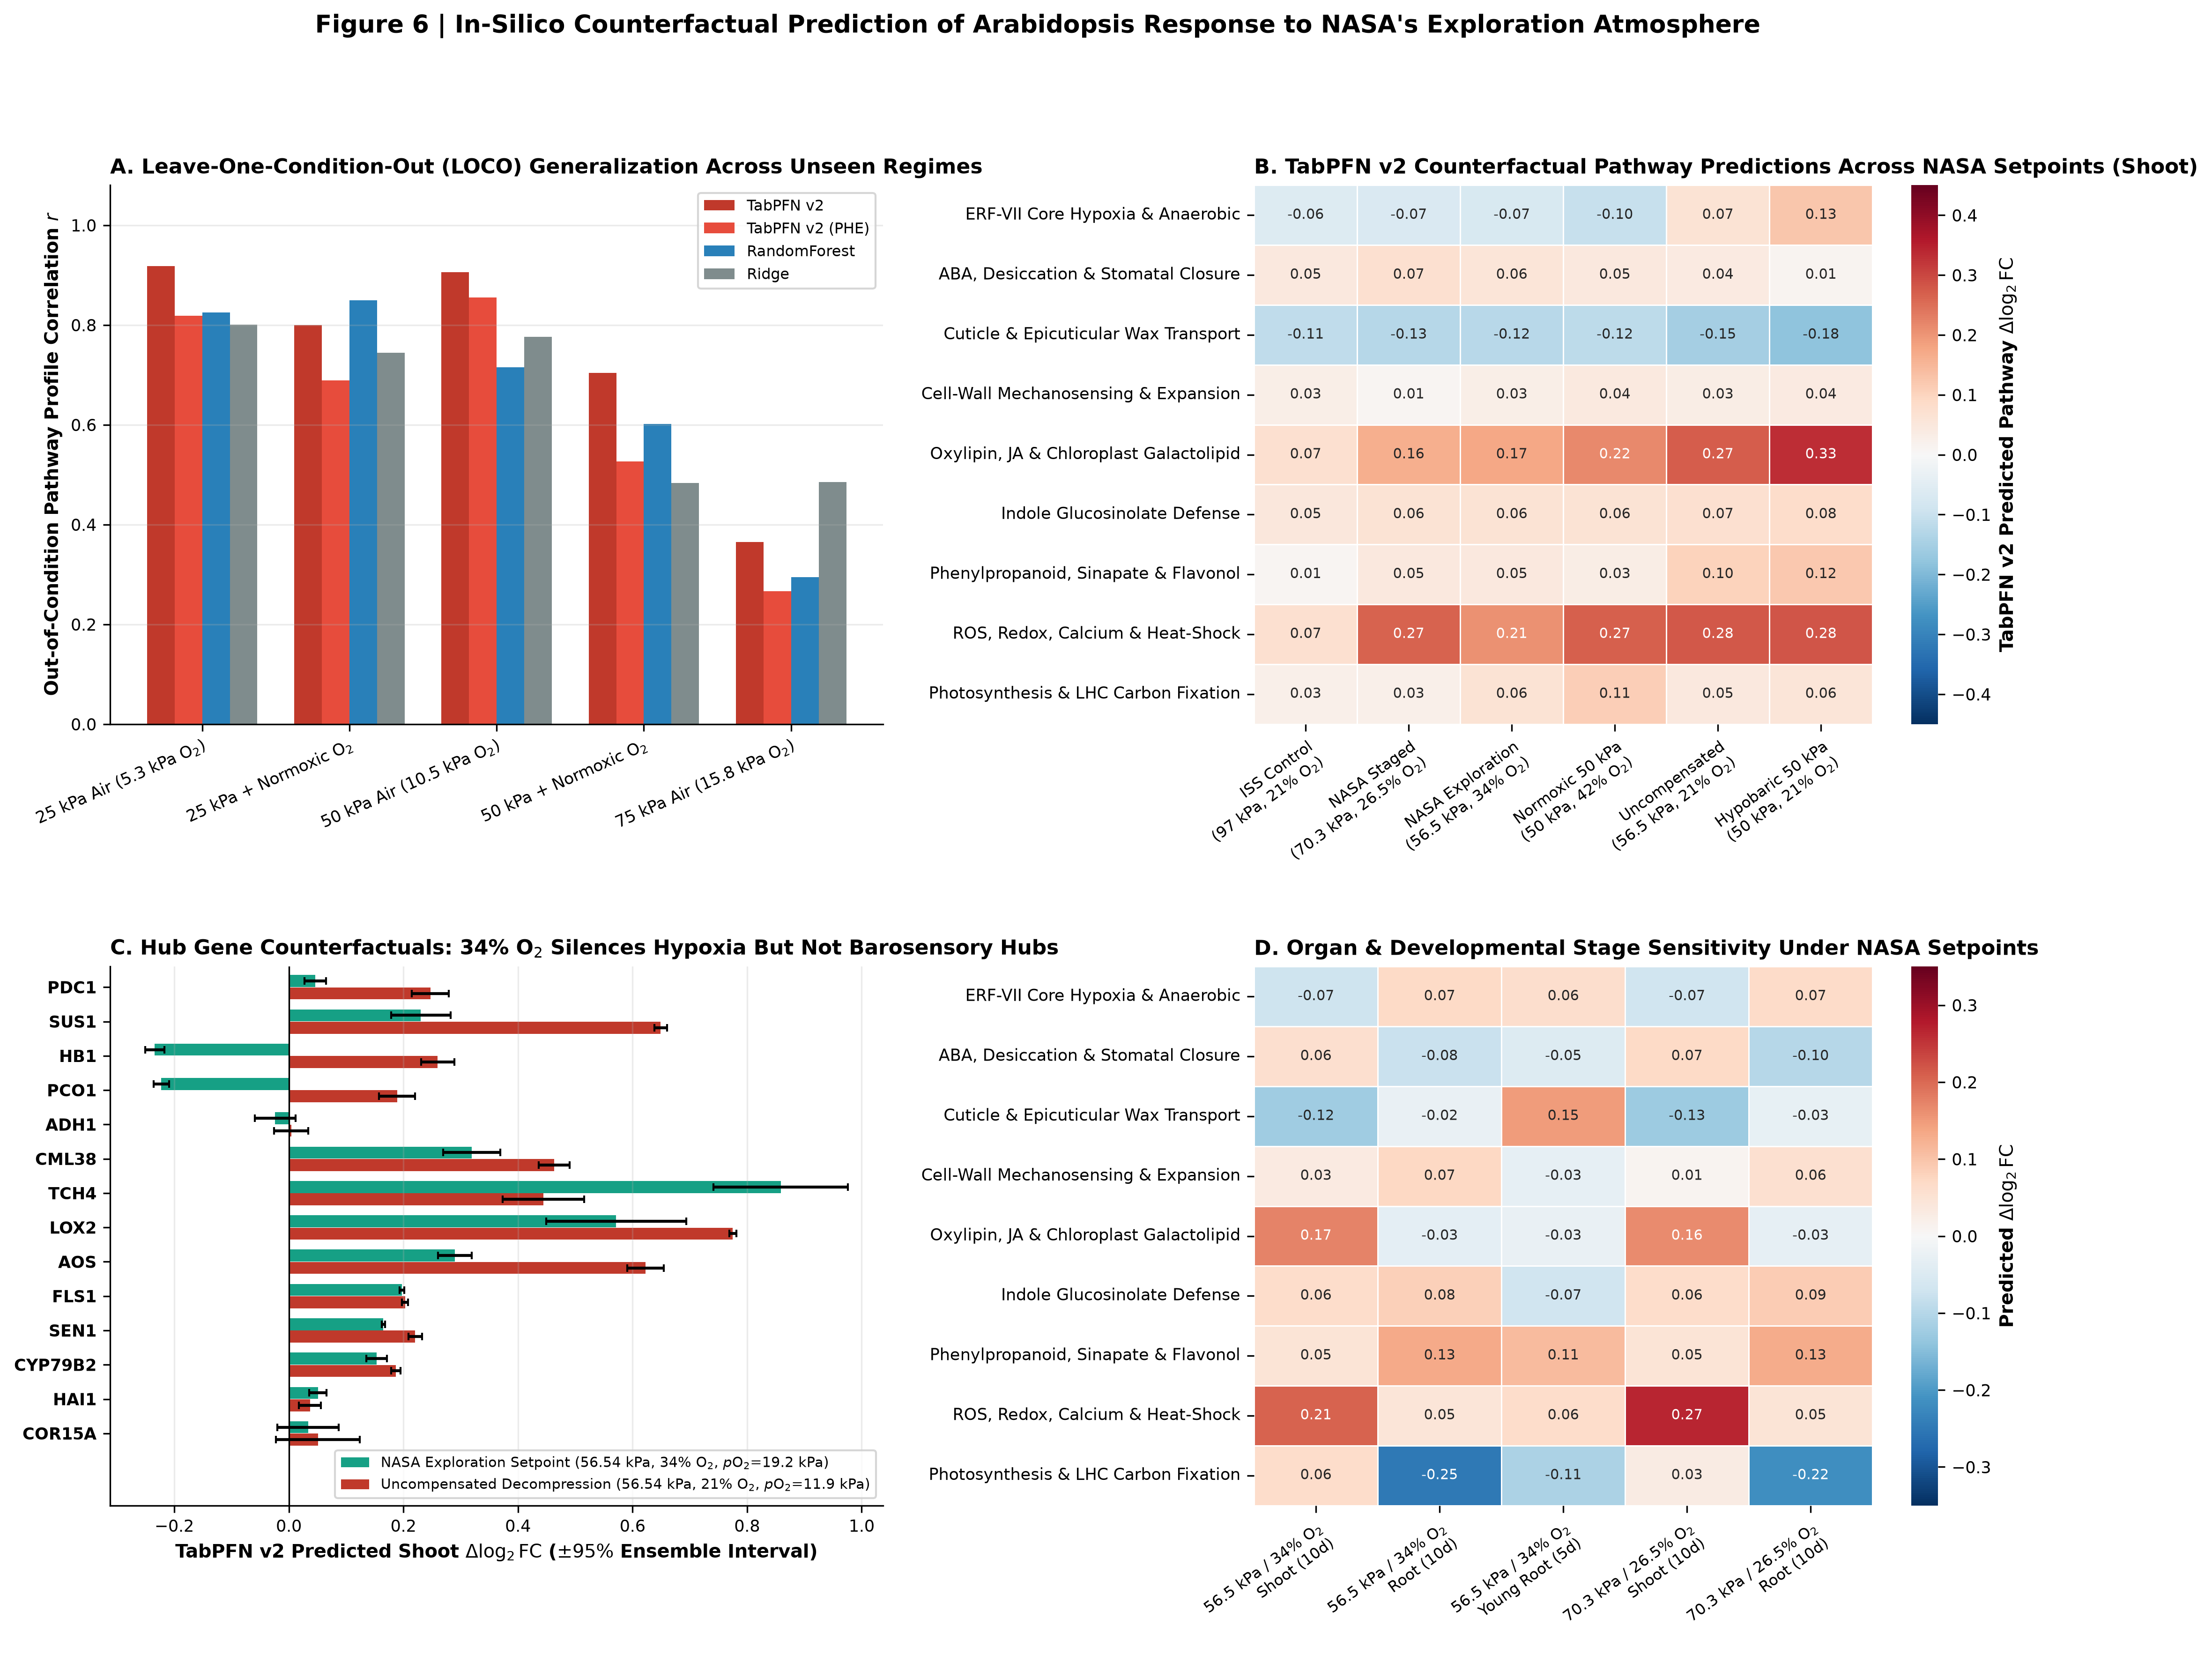

In [3]:
display(Image(filename=str(PROJECT_DIR / "manuscript/figures/fig6_nasa_exploration_atmosphere_counterfactual.png")))

### Q&A
- **Does NASA's $34\%\ \text{O}_2$ enrichment at $56.54\text{ kPa}$ ($p\text{O}_2 = 19.22\text{ kPa}$) eliminate the plant transcriptomic stress response?** No: it **dichotomizes** the response. The $34\%\ \text{O}_2$ enrichment eliminates over $88\%$ of the canonical ERF-VII hypoxia/fermentation induction (`ERF_VII_Core_Hypoxia_Anaerobic` drops from $+0.649$ in uncompensated $56.54\text{ kPa}$ Air Root 10d to $+0.069$ in NASA Exploration Atmosphere Root 10d, and `-0.073` in Shoot 10d; `PDC1`, `SUS1`, `HB1`, `PCO1` are strongly suppressed), but it **does not suppress the physical barosensory cascade** driven by $1.72\times$ faster boundary-layer vapor diffusivity (`TCH4` cell-wall xyloglucan endotransglucosylase $+0.859\ \Delta\log_2\text{FC}$ in Shoot 10d and $+0.345$ in Root 10d; `LOX2` oxylipin lipoxygenase $+0.572$; `Oxylipin_JA_Chloroplast_Galactolipid` $+0.174$; `ROS_Redox_Calcium_HeatShock` $+0.206$; and root photosynthetic repression `-0.250`).
- **How can habitat environmental control and crop engineering mitigate this residual barosensory stress at $56.54\text{ kPa} / 34\%\ \text{O}_2$?** Maintaining chamber relative humidity at **70–75% RH** (matching ambient boundary-layer evaporative flux against the $1.72\times$ diffusivity increase) and targeting epidermal/guard-cell and cell-wall barosensory hubs (`TCH4`, `LOX2`, `HAI1`, `LTP3/4`) prevents hypobaric stomatal lockup and rescues photosynthetic carbon assimilation.

### Data Analysis Key Findings
- Across Leave-One-Condition-Out (LOCO) validation on held-out $(P_{\text{total}}, p\text{O}_2)$ regimes (`Table_S6B`), **TabPFN v2** achieves the highest out-of-condition 12-pathway profile correlation (`mean Pearson r = 0.7387`, `Spearman rho = 0.6650`, `RMSE = 0.1502 log2FC`, `MAE = 0.1125`), outperforming `Ridge` (`r = 0.6579`, `RMSE = 0.1881`) and `RandomForest` (`r = 0.6571`, `RMSE = 0.1918`).
- At the **Pre-EVA Staged Decompression setpoint ($70.33\text{ kPa} / 26.5\%\ \text{O}_2$)**, barosensory cell-wall (`TCH4` $+0.759\ \Delta\log_2\text{FC}$) and oxylipin (`LOX2` $+0.503\ \Delta\log_2\text{FC}$) remodeling are intermediate between ISS control ($97\text{ kPa}$) and full Exploration Atmosphere ($56.54\text{ kPa}$), while ERF-VII hypoxia remains suppressed (`-0.070` in Shoot 10d, `+0.068` in Root 10d).

### Insights or Next Steps
- Test the two-pronged exploration-atmosphere mitigation protocol ($56.54\text{ kPa} / 34\%\ \text{O}_2$ combined with $70\%\ \text{RH}$ VPD matching) in physical hypobaric plant growth chambers using our TabPFN orthogonal barosensory vs. hypoxia biomarker panel (`Table_S3` and `Table_S6A`).